# 05 Ikaskuntza gainbegiratu gabea: K-means

Barakaldon ingurumen-egoera tipikoak aurkitu nahi ditugu, etiketarik gabe: trafikoko puntako orduak, aire garbia, kutsadura-episodioak... K-meansek orduak K taldetan banatzen ditu, ordu bakoitza bere taldearen zentroidetik ahalik eta hurbilen gera dadin.

In [1]:
# Liburutegiak
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, homogeneity_score, completeness_score, v_measure_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Aldagaiak eta prestaketa

Uneko orduko neurketak bakarrik erabiltzen ditugu (kutsatzaileak eta meteorologia), ez ordua ez hilabetea. Horrela gero egiazta dezakegu taldeek zentzua dutela egutegian.

K-meansek distantziak neurtzen dituenez, nuluak medianarekin betetzen ditugu eta estandarizatzen dugu (bestela hezetasunak, 0-100 tartearekin, COak baino askoz pisu handiagoa izango luke). 2023-2025ekin entrenatzen dugu eta 2026 gordetzen dugu egiaztatzeko.

In [2]:
entrenamendua = pd.read_csv("../data/prozesatuak/barakaldo_entrenamendua.csv", index_col="data", parse_dates=True)
proba = pd.read_csv("../data/prozesatuak/barakaldo_proba.csv", index_col="data", parse_dates=True)

CLUSTER_ALDAGAIAK = ["NO2", "NO", "CO", "SO2", "PM10", "PM25", "tenperatura", "hezetasuna", "haize_abiadura"]

prestaketa = Pipeline([
    ("inputatu", SimpleImputer(strategy="median")),
    ("eskalatu", StandardScaler()),
])
X_entr = prestaketa.fit_transform(entrenamendua[CLUSTER_ALDAGAIAK])
X_proba = prestaketa.transform(proba[CLUSTER_ALDAGAIAK])

print("Entrenamendua:", X_entr.shape, "| Proba:", X_proba.shape)

Entrenamendua: (26039, 9) | Proba: (7253, 9)


## 2. K aukeratzea

- Ukondoaren metodoa: inertzia K = 2tik 10era, eta asko jaisteari uzten dion puntua bilatzen dugu.
- Silhouettea: ordu bakoitza bere taldetik beste taldeetatik baino gertuago dagoen (-1etik 1era, handiagoa hobea). Motela denez, 6.000 orduko lagin batekin kalkulatzen dugu.

In [ ]:
k_balioak = range(2, 11)
inertziak = []
silhouetteak = []

#Lagin finkoa silhouetterako
lagina = np.random.RandomState(42).choice(len(X_entr), 6000, replace=False)

for k in k_balioak:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_entr)
    inertziak.append(kmeans.inertia_)
    silhouetteak.append(silhouette_score(X_entr[lagina], kmeans.labels_[lagina]))
    print("K =", k, "| inertzia:", round(kmeans.inertia_), "| silhouette:", round(silhouetteak[-1], 3))

K = 2 | inertzia: 188768 | silhouette: 0.272


K = 3 | inertzia: 166961 | silhouette: 0.163


K = 4 | inertzia: 151577 | silhouette: 0.172


K = 5 | inertzia: 140374 | silhouette: 0.165


K = 6 | inertzia: 131802 | silhouette: 0.158


K = 7 | inertzia: 123522 | silhouette: 0.153


K = 8 | inertzia: 117914 | silhouette: 0.132


K = 9 | inertzia: 114072 | silhouette: 0.125


K = 10 | inertzia: 108941 | silhouette: 0.131


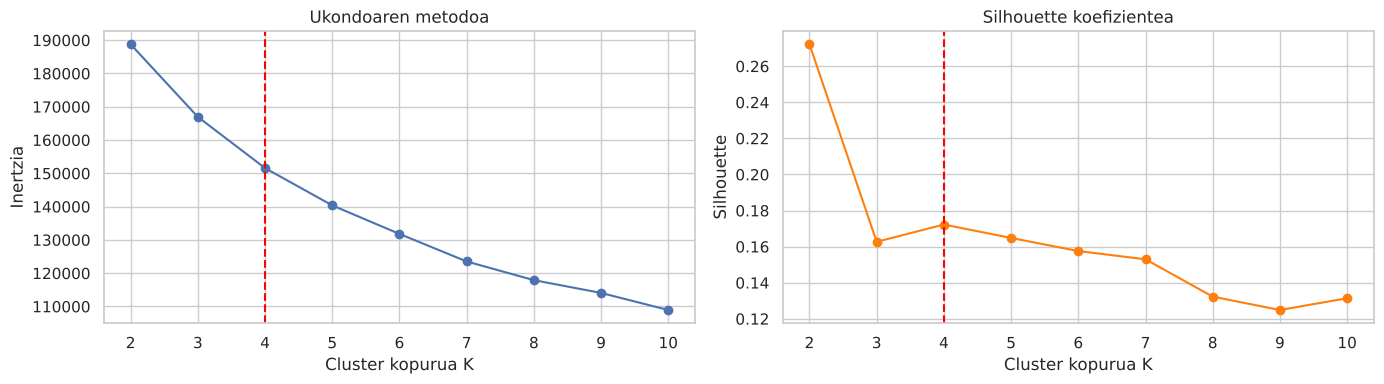

In [ ]:
fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
ardatzak[0].plot(list(k_balioak), inertziak, marker="o")
ardatzak[0].set_title("Ukondoaren metodoa")
ardatzak[0].set_xlabel("Cluster kopurua K")
ardatzak[0].set_ylabel("Inertzia")
ardatzak[0].axvline(4, color="red", linestyle="--")
ardatzak[1].plot(list(k_balioak), silhouetteak, marker="o", color="tab:orange")
ardatzak[1].set_title("Silhouette koefizientea")
ardatzak[1].set_xlabel("Cluster kopurua K")
ardatzak[1].set_ylabel("Silhouette")
ardatzak[1].axvline(4, color="red", linestyle="--")

plt.tight_layout()
plt.show()

#### K = 4 aukeratzen dugu

K = 2k du silhouette altuena (0,27), baina ordu garbiak eta kutsatuak bakarrik bereizten ditu. 3 eta 7 artean K = 4 da onena (0,172), eta ukondoa hortik aurrera leuntzen da. Gainera, lau taldeak interpreta daitezke.

Silhouette baxua da, ingurumen-datuak pixkanaka aldatzen direlako eta taldeak elkarri itsatsita daudelako. Normala da mota honetako datuetan.

## 3. K-means entrenatzea K = 4rekin

In [5]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
kmeans.fit(X_entr)

entrenamendua = entrenamendua.copy()
entrenamendua["clusterra"] = kmeans.labels_
entrenamendua["clusterra"].value_counts().sort_index()

clusterra
0     3395
1    11777
2     3200
3     7667
Name: count, dtype: int64

In [6]:
# Zentroideak jatorrizko unitateetan (estandarizazioa desegiten dugu)
eskalatzailea = prestaketa.named_steps["eskalatu"]
zentroideak = pd.DataFrame(eskalatzailea.inverse_transform(kmeans.cluster_centers_), columns=CLUSTER_ALDAGAIAK)
zentroideak["orduak"] = entrenamendua["clusterra"].value_counts().sort_index().values
zentroideak["% orduak"] = (100 * zentroideak["orduak"] / len(entrenamendua)).round(1)
zentroideak.round(1)

,NO2,NO,CO,SO2,PM10,PM25,tenperatura,hezetasuna,haize_abiadura,orduak,% orduak
0,39.9,19.0,0.3,10.4,26.6,11.1,13.0,74.2,1.0,3395,13.0
1,17.4,2.4,0.2,5.2,16.7,6.8,14.9,77.0,1.1,11777,45.2
2,21.5,3.4,0.3,5.7,37.5,20.1,21.4,67.3,1.3,3200,12.3
3,9.2,1.6,0.2,5.1,15.8,5.6,18.4,56.4,2.1,7667,29.4


### Taldeen izenak

K-meansek taldeak ausaz zenbakitzen ditu; horregatik izenak zentroideetatik abiatuta jartzen ditugu:

1. PM10 gehien duena → Partikula-episodioa
2. Geratzen direnetatik NO2 gehien duena → Trafikoko puntako ordua
3. Geratzen direnetatik haize gehien duena → Aire garbia haizearekin
4. Geratzen dena → Gaueko bareta

In [ ]:
cluster_izenak = {}
falta_direnak = list(range(K))

# 1) PM10 gehien
c = int(zentroideak.loc[falta_direnak, "PM10"].idxmax())
cluster_izenak[c] = "Partikula-episodioa"
falta_direnak.remove(c)

# 2) NO2 gehien
c = int(zentroideak.loc[falta_direnak, "NO2"].idxmax())
cluster_izenak[c] = "Trafikoko puntako ordua"
falta_direnak.remove(c)

# 3)Haize gehien
c = int(zentroideak.loc[falta_direnak, "haize_abiadura"].idxmax())
cluster_izenak[c] = "Aire garbia haizearekin"
falta_direnak.remove(c)

# 4)Geratzen dena
cluster_izenak[falta_direnak[0]] = "Gaueko bareta"

print(cluster_izenak)
entrenamendua["egoera"] = entrenamendua["clusterra"].map(cluster_izenak)
zentroideak.index = [cluster_izenak[i] for i in zentroideak.index]
ORDENA = ["Aire garbia haizearekin", "Gaueko bareta", "Trafikoko puntako ordua", "Partikula-episodioa"]
zentroideak.loc[ORDENA].round(1)

{2: 'Partikula-episodioa', 0: 'Trafikoko puntako ordua', 3: 'Aire garbia haizearekin', 1: 'Gaueko bareta'}


,NO2,NO,CO,SO2,PM10,PM25,tenperatura,hezetasuna,haize_abiadura,orduak,% orduak
Aire garbia haizearekin,9.2,1.6,0.2,5.1,15.8,5.6,18.4,56.4,2.1,7667,29.4
Gaueko bareta,17.4,2.4,0.2,5.2,16.7,6.8,14.9,77.0,1.1,11777,45.2
Trafikoko puntako ordua,39.9,19.0,0.3,10.4,26.6,11.1,13.0,74.2,1.0,3395,13.0
Partikula-episodioa,21.5,3.4,0.3,5.7,37.5,20.1,21.4,67.3,1.3,3200,12.3


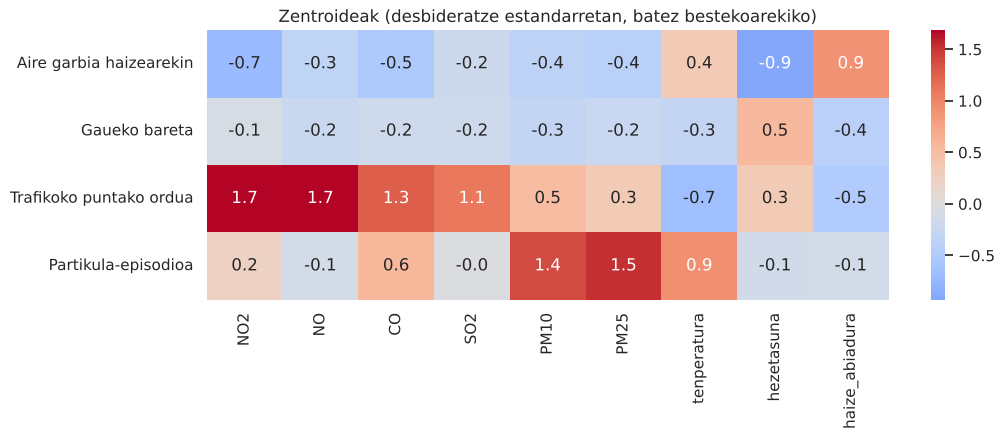

In [8]:
# Zentroide estandarizatuen bero-mapa (0 = batez bestekoa, >0 gainetik, <0 azpitik)
zentroideak_z = pd.DataFrame(kmeans.cluster_centers_, columns=CLUSTER_ALDAGAIAK,
                             index=[cluster_izenak[i] for i in range(K)]).loc[ORDENA]
plt.figure(figsize=(11, 3.5))
sns.heatmap(zentroideak_z, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Zentroideak (desbideratze estandarretan, batez bestekoarekiko)")
plt.show()

## 4. Clusterren interpretazioa

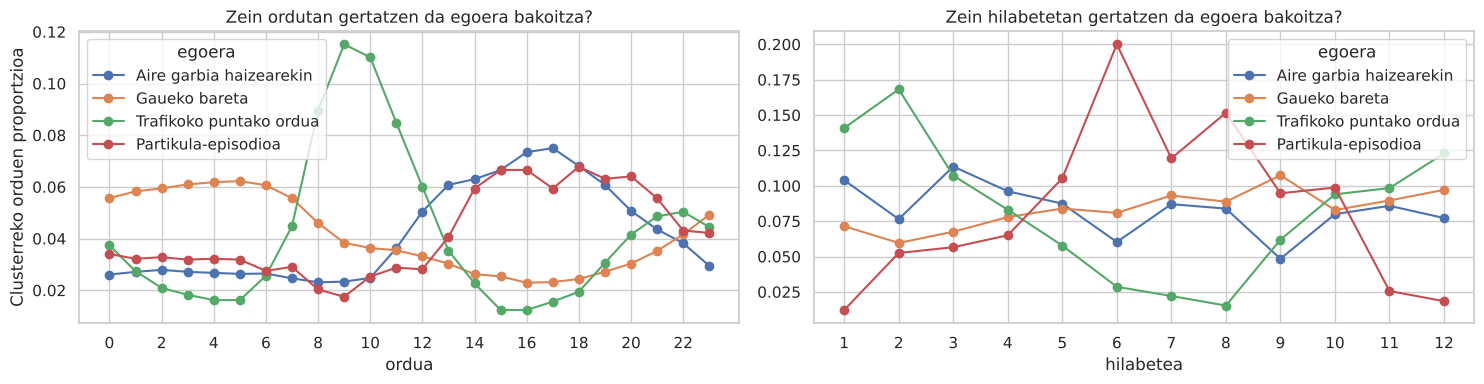

In [9]:
entrenamendua["ordua"] = entrenamendua["ordua"].astype(int)

fig, ardatzak = plt.subplots(1, 2, figsize=(15, 4))
orduka = pd.crosstab(entrenamendua["ordua"], entrenamendua["egoera"], normalize="columns")[ORDENA]
orduka.plot(ax=ardatzak[0], marker="o")
ardatzak[0].set_title("Zein ordutan gertatzen da egoera bakoitza?")
ardatzak[0].set_ylabel("Clusterreko orduen proportzioa")
ardatzak[0].set_xticks(range(0, 24, 2))

hilabeteka = pd.crosstab(entrenamendua["hilabetea"], entrenamendua["egoera"], normalize="columns")[ORDENA]
hilabeteka.plot(ax=ardatzak[1], marker="o")
ardatzak[1].set_title("Zein hilabetetan gertatzen da egoera bakoitza?")
ardatzak[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [10]:
# Egoera bakoitzaren asteburua eta ICA kategoria
laburpena = pd.DataFrame({
    "% asteburua": ((entrenamendua["aste_eguna"] >= 5).groupby(entrenamendua["egoera"]).mean() * 100).round(1),
    "ordu ohikoena": entrenamendua.groupby("egoera")["ordua"].agg(lambda x: x.mode()[0]),
    "hilabete ohikoena": entrenamendua.groupby("egoera")["hilabetea"].agg(lambda x: x.mode()[0]),
}).loc[ORDENA]
laburpena

,% asteburua,ordu ohikoena,hilabete ohikoena
egoera,,,
Aire garbia haizearekin,31.6,17,3
Gaueko bareta,30.6,5,9
Trafikoko puntako ordua,17.3,9,2
Partikula-episodioa,26.3,18,6


In [11]:
ica = (pd.crosstab(entrenamendua["egoera"], entrenamendua["ICA_estazioa"], normalize="index") * 100).round(1)
ica.loc[ORDENA, ["Oso ona", "Ona", "Erregularra", "Txarra"]]

ICA_estazioa,Oso ona,Ona,Erregularra,Txarra
egoera,,,,
Aire garbia haizearekin,72.8,24.9,1.8,0.5
Gaueko bareta,69.2,28.4,2.1,0.3
Trafikoko puntako ordua,25.4,65.0,8.9,0.7
Partikula-episodioa,11.8,55.9,22.9,9.4


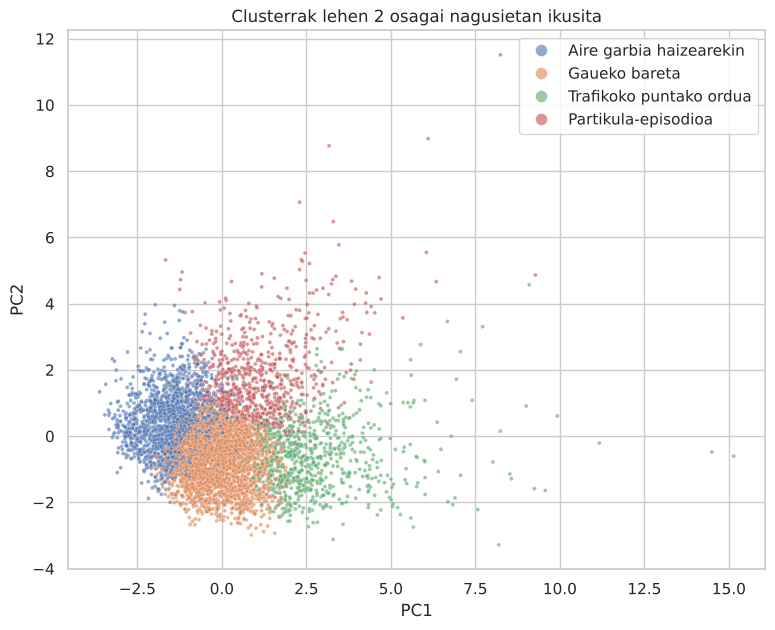

In [12]:
# 2 dimentsiotako bistaratzea PCArekin (marrazteko bakarrik)
pca = PCA(n_components=2)
puntuak = pca.fit_transform(X_entr)
marrazkia = pd.DataFrame({"PC1": puntuak[:, 0], "PC2": puntuak[:, 1], "egoera": entrenamendua["egoera"].values})
marrazkia = marrazkia.sample(6000, random_state=42)

plt.figure(figsize=(9, 7))
sns.scatterplot(data=marrazkia, x="PC1", y="PC2", hue="egoera", hue_order=ORDENA, s=8, alpha=0.6)
plt.title("Clusterrak lehen 2 osagai nagusietan ikusita")
plt.legend(markerscale=3)
plt.show()

#### Egoerak

| Egoera | Nolakoa | Noiz | Kalitatea |
|---|---|---|---|
| Aire garbia haizearekin (% 29) | Haize indartsua (≈ 2,1 m/s), NO2 baxua (≈ 9) | Arratsaldeak, urte osoan | Ia beti ona |
| Gaueko bareta (% 45) | Haize ahula, hezetasun altua (≈ % 77) | Gauak eta goizaldeak | Ona |
| Trafikoko puntako ordua (% 13) | NO2 ≈ 40, NO ≈ 19, hotza eta haizerik gabe | Laneguneko goizak (9:00 aldera), neguan | Gehienetan "Ona" |
| Partikula-episodioa (% 12) | PM10 ≈ 38, PM2.5 ≈ 20, beroa | Udaberri eta udako arratsaldeak | Ordu Erregular eta Txar gehien (% 32) |

Trafikoko puntako orduak neguan gertatzen dira, goiz hotz eta bareetan alderantzizko termikoak kutsadura lurraren ondoan harrapatzen duelako. Partikula-episodioak, berriz, udan. Egutegia ereduan sartu gabe taldeak orduaren eta hilabetearen arabera hain ondo ordenatzeak esan nahi du egoera errealak direla.

## 5. 2026ko datuekin balioztapena

Probako datuekin begiratzen dugu taldeek kalitate bera duten, antzeko proportzioetan agertzen diren eta gauza bera esan nahi duten.

In [13]:
proba = proba.copy()
proba["clusterra"] = kmeans.predict(X_proba)
proba["egoera"] = proba["clusterra"].map(cluster_izenak)

proba_lagina = np.random.RandomState(42).choice(len(X_proba), 6000, replace=False)
print("Silhouette entrenamendua:", round(silhouette_score(X_entr[lagina], kmeans.labels_[lagina]), 3))
print("Silhouette proba:        ", round(silhouette_score(X_proba[proba_lagina], proba["clusterra"].values[proba_lagina]), 3))

pd.DataFrame({
    "% orduak entrenamendua": (entrenamendua["egoera"].value_counts(normalize=True) * 100).round(1),
    "% orduak proba": (proba["egoera"].value_counts(normalize=True) * 100).round(1),
}).loc[ORDENA]

Silhouette entrenamendua: 0.172


Silhouette proba:         0.172


,% orduak entrenamendua,% orduak proba
egoera,,
Aire garbia haizearekin,29.4,18.3
Gaueko bareta,45.2,54.3
Trafikoko puntako ordua,13.0,10.7
Partikula-episodioa,12.3,16.7


In [14]:
# Talde bakoitzaren batez bestekoak entrenamenduan eta proban
alderaketa = pd.concat([
    entrenamendua.groupby("egoera")[["NO2", "PM10", "PM25", "haize_abiadura", "tenperatura"]].mean().add_suffix(" (entr)"),
    proba.groupby("egoera")[["NO2", "PM10", "PM25", "haize_abiadura", "tenperatura"]].mean().add_suffix(" (proba)"),
], axis=1)
alderaketa = alderaketa[[z + a for z in ["NO2", "PM10", "PM25", "haize_abiadura", "tenperatura"] for a in [" (entr)", " (proba)"]]]
alderaketa.loc[ORDENA].round(1)

,NO2 (entr),NO2 (proba),PM10 (entr),PM10 (proba),PM25 (entr),PM25 (proba),haize_abiadura (entr),haize_abiadura (proba),tenperatura (entr),tenperatura (proba)
egoera,,,,,,,,,,
Aire garbia haizearekin,9.2,10.1,15.2,14.6,5.5,5.4,2.1,2.4,18.4,16.1
Gaueko bareta,17.4,16.0,16.3,17.6,6.8,7.1,1.1,1.2,14.8,14.9
Trafikoko puntako ordua,39.9,41.9,27.6,30.1,11.4,11.7,1.0,1.1,12.8,13.6
Partikula-episodioa,21.5,22.1,41.1,41.5,20.1,19.8,1.3,1.3,21.7,20.4


In [15]:
# Talde bakoitzaren silhouettea (zein talde dauden hobeto definituta)
balioak = silhouette_samples(X_proba[proba_lagina], proba["clusterra"].values[proba_lagina])
pd.Series(balioak).groupby(proba["egoera"].values[proba_lagina]).mean().loc[ORDENA].round(3)

Aire garbia haizearekin    0.107
Gaueko bareta              0.245
Trafikoko puntako ordua    0.010
Partikula-episodioa        0.112
dtype: float64

#### Emaitza

- 2026ko silhouettea entrenamendukoaren berdina da (0,172): taldeek balio dute datu berriekin.
- Partikula-episodio gehiago dago (% 17, % 12ren aldean), 2026an airea okerragoa izan delako.
- Aire garbia haizearekin gutxiago dago (% 18, % 29ren aldean). Neurri batean 2026an falta diren haize-datuengatik da: medianarekin betetzen dira (≈ 1,2 m/s) eta ordu horiek Gaueko bareta taldera joaten dira.
- Talde bakoitzak ezaugarri berberak ditu 2026an.

## 6. Beste clustering algoritmo batzuekin alderaketa

Clustering hierarkikoa (Ward) eta gaussiar nahasketa (GMM) probatzen ditugu aldagai berberekin. Hierarkikoa motela denez, 6.000 orduko laginarekin egiten dugu.

Alderatzeko silhouettea eta gaian ikusitako homogeneity, completeness eta v-measure erabiltzen ditugu, K-meansen taldeak erreferentzia gisa hartuta (1 = talde berberak).

In [16]:
# Hiru algoritmoak K = 4rekin
gmm = GaussianMixture(n_components=4, random_state=42, n_init=2)
gmm_taldeak = gmm.fit_predict(X_entr)

hierarkikoa = AgglomerativeClustering(n_clusters=4, linkage="ward")
hierarkiko_taldeak = hierarkikoa.fit_predict(X_entr[lagina])

# K-meansen taldeak erreferentzia gisa hartuta, beste bi algoritmoen taldeak zenbateraino datozen bat
kmeans_taldeak = kmeans.labels_
algoritmoen_alderaketa = pd.DataFrame({
    "silhouette (lagina)": [silhouette_score(X_entr[lagina], kmeans_taldeak[lagina]),
                            silhouette_score(X_entr[lagina], hierarkiko_taldeak),
                            silhouette_score(X_entr[lagina], gmm_taldeak[lagina])],
    "homogeneity": [1.0,
                    homogeneity_score(kmeans_taldeak[lagina], hierarkiko_taldeak),
                    homogeneity_score(kmeans_taldeak, gmm_taldeak)],
    "completeness": [1.0,
                     completeness_score(kmeans_taldeak[lagina], hierarkiko_taldeak),
                     completeness_score(kmeans_taldeak, gmm_taldeak)],
    "v_measure": [1.0,
                  v_measure_score(kmeans_taldeak[lagina], hierarkiko_taldeak),
                  v_measure_score(kmeans_taldeak, gmm_taldeak)],
    "ordu berriei aplika dakieke": ["bai", "ez", "bai"],
}, index=["K-means", "Hierarkikoa (Ward)", "Gaussiar nahasketa"])
algoritmoen_alderaketa.round(3)

,silhouette (lagina),homogeneity,completeness,v_measure,ordu berriei aplika dakieke
K-means,0.172,1.000,1.000,1.000,bai
Hierarkikoa (Ward),0.098,0.442,0.442,0.442,ez
Gaussiar nahasketa,0.066,0.376,0.365,0.371,bai


In [17]:
# Gaussiar nahasketako talde bakoitza K-meanseko zein egoerarekin datorren bat (errenkada bakoitzaren %)
pd.crosstab(entrenamendua["egoera"], gmm_taldeak, normalize="index").loc[ORDENA].round(2)

col_0,0,1,2,3
egoera,,,,
Aire garbia haizearekin,0.08,0.08,0.84,0.00
Gaueko bareta,0.51,0.07,0.38,0.05
Trafikoko puntako ordua,0.08,0.06,0.00,0.86
Partikula-episodioa,0.09,0.72,0.12,0.07


#### Emaitza

- K-meansek du silhouette altuena (0,17; hierarkikoak 0,10 eta GMMk 0,07).
- Hierarkikoa nahiko antzekoa da K-meansen (v-measure0,44), baina laginarekin bakarrik egin daiteke eta ez daki ordu berriak taldeetan sartzen.
- GMMk K = 4rekin egoera berberak aurkitzen ditu neurri batean (Trafikoko puntako orduaren % 86, Aire garbiaren % 84 eta Partikula-episodioaren % 72 talde bakarrean), baina Gaueko bareta bitan banatzen du (v-measure 0,37).

K-meansekin geratzen gara: talde bereizienak, interpretatzeko errazak, eta Jetsonen ordu berri bakoitzari aplika dakioke 4 zentroideetarako distantzia kalkulatuta.

## 7. Ondorioak

- K-meansek (K = 4) zentzu fisikoa duten lau egoera aurkitzen ditu egutegia eta ICA erabili gabe: aire garbia, gaueko bareta, trafikoko puntako ordua (alderantzizko termikoarekin) eta partikula-episodioa.
- Silhouettea baxua da (0,17), baina taldeak 2026an mantentzen dira.
- Aginte-panelak "zein egoeratan gauden" erakusten du, eta sistema adituak bere arauetan erabiltzen du.

In [18]:
cluster_eredua = Pipeline([
    ("prestaketa", prestaketa),
    ("kmeans", kmeans),
])
joblib.dump(cluster_eredua, "../ereduak/kmeans_egoerak.joblib")
joblib.dump({"aldagaiak": CLUSTER_ALDAGAIAK, "izenak": cluster_izenak}, "../ereduak/kmeans_info.joblib")
print("Gordeta: ereduak/kmeans_egoerak.joblib eta ereduak/kmeans_info.joblib")

# Egiaztapena: gordetako ereduak talde berberak ematen ditu
kargatua = joblib.load("../ereduak/kmeans_egoerak.joblib")
print("Emaitza bera proban:", (kargatua.predict(proba[CLUSTER_ALDAGAIAK]) == proba["clusterra"]).all())

Gordeta: ereduak/kmeans_egoerak.joblib eta ereduak/kmeans_info.joblib
Emaitza bera proban: True
